In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report


In [2]:
train_df = pd.read_csv('sign_mnist_train.csv')
test_df  = pd.read_csv('sign_mnist_test.csv')

In [3]:
# FIX: fillna(0) instead of dropna() — avoids silently losing rows
train_df = train_df.fillna(0)
test_df  = test_df.fillna(0)

# ---------- Separate labels / pixels ----------
y_train_raw = train_df['label'].values.astype(int)
x_train     = train_df.drop('label', axis=1).values.astype(float)

y_test_raw  = test_df['label'].values.astype(int)
x_test      = test_df.drop('label', axis=1).values.astype(float)

# ---------- FIX: robust label remap (Req 6: 24 classes) ----------
# Dataset has labels 0–24 with label 9 missing → remap to 0–23
label_map = {label: idx for idx, label in enumerate(sorted(np.unique(y_train_raw)))}
y_train   = np.array([label_map[v] for v in y_train_raw])
y_test    = np.array([label_map[v] for v in y_test_raw])

# ---------- REQ 8: Normalize pixels to [0, 1] ----------
x_train = x_train / 255.0
x_test  = x_test  / 255.0

# ---------- REQ 6: Reshape to 28 × 28 × 1 ----------
x_train = x_train.reshape(-1, 28, 28, 1)
x_test  = x_test.reshape(-1, 28, 28, 1)

# ---------- FIX: correct alphabet (J and Z excluded) ----------
alphabet = [chr(i + 65) for i in range(26) if chr(i + 65) not in ['J', 'Z']]
assert len(alphabet) == 24

print(f"Train: {x_train.shape}, Test: {x_test.shape}")
print(f"Classes: {len(alphabet)} → {alphabet}")

Train: (27455, 28, 28, 1), Test: (7172, 28, 28, 1)
Classes: 24 → ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y']


In [4]:
# ---------- REQ 6, 7, 10: CNN with Conv2D → MaxPooling2D → Flatten → Dense ----------
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Feature extraction block 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Feature extraction block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Feature extraction block 3
    layers.Conv2D(64, (3, 3), activation='relu'),

    # REQ 10: extracted features → classification head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(24, activation='softmax')   # 24 ASL letters (A–Y, no J/Z)
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 3, 3, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 132,696 (518.34 KB)

 Trainable params: 132,696 (518.34 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,   # 10% of TRAIN used for validation (test set untouched)
    verbose=1
)

Epoch 1/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.6021 - loss: 1.2951 - val_accuracy: 0.8995 - val_loss: 0.3365
Epoch 2/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9537 - loss: 0.1620 - val_accuracy: 0.9927 - val_loss: 0.0448
Epoch 3/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - accuracy: 0.9968 - loss: 0.0244 - val_accuracy: 1.0000 - val_loss: 0.0084
Epoch 4/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - accuracy: 0.9951 - loss: 0.0227 - val_accuracy: 0.9803 - val_loss: 0.0641
Epoch 5/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9990 - loss: 0.0059 - val_accuracy: 1.0000 - val_loss: 0.0012
Epoch 6/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 1.0000 - loss: 8.5742e-04 - val_accuracy: 1.0000 - val_loss: 7.0066e-04
Epoch 7/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 1.0000 - loss: 5.3171e-04 - val_accuracy: 1.0000 - val_loss: 6.0581e-04
Epoch 8/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 1.0000 -

In [6]:
# Test set is evaluated exactly ONCE — after training — so the number is honest
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Final Test Accuracy: {test_acc*100:.2f}%")
print(f"Final Test Loss:     {test_loss:.4f}")
print(f"Final Train Accuracy:{history.history['accuracy'][-1]*100:.2f}%")
print(f"Best Val Accuracy:   {max(history.history['val_accuracy'])*100:.2f}%")

Final Test Accuracy: 91.77%
Final Test Loss:     0.4445
Final Train Accuracy:100.00%
Best Val Accuracy:   100.00%


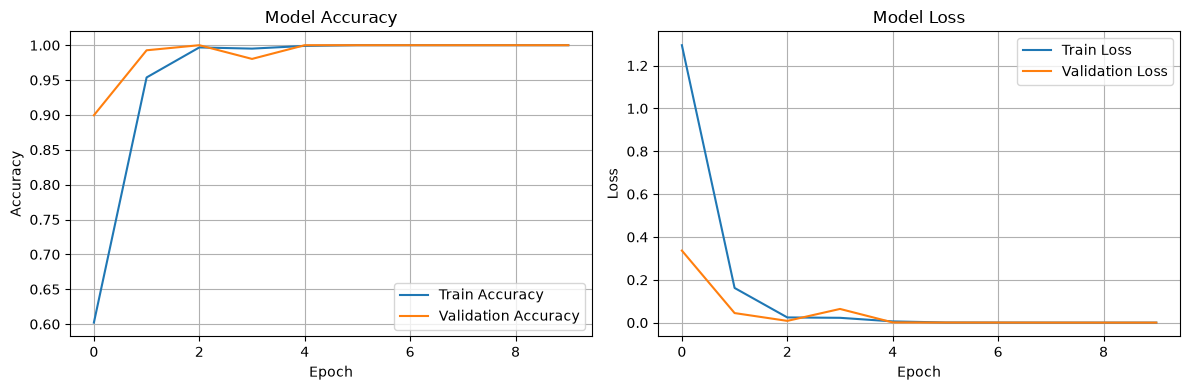

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy graph
ax1.plot(history.history['accuracy'],     label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy')
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss graph
ax2.plot(history.history['loss'],     label='Train Loss')
ax2.plot(history.history['val_loss'], label='Validation Loss')
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

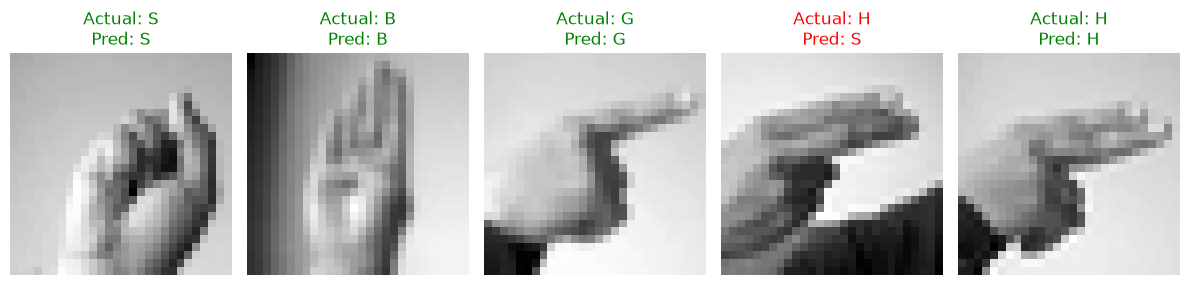

In [8]:
# Random 5 test samples (seeded for reproducibility)
rng     = np.random.default_rng(42)
indices = rng.choice(len(x_test), 5, replace=False)

predictions       = model.predict(x_test[indices], verbose=0)
predicted_classes = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 3))
for i, idx in enumerate(indices):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[idx].reshape(28, 28), cmap='gray')

    actual_char = alphabet[y_test[idx]]
    pred_char   = alphabet[predicted_classes[i]]
    color       = 'green' if actual_char == pred_char else 'red'

    plt.title(f"Actual: {actual_char}\nPred: {pred_char}", color=color)
    plt.axis('off')

plt.tight_layout()
plt.show()

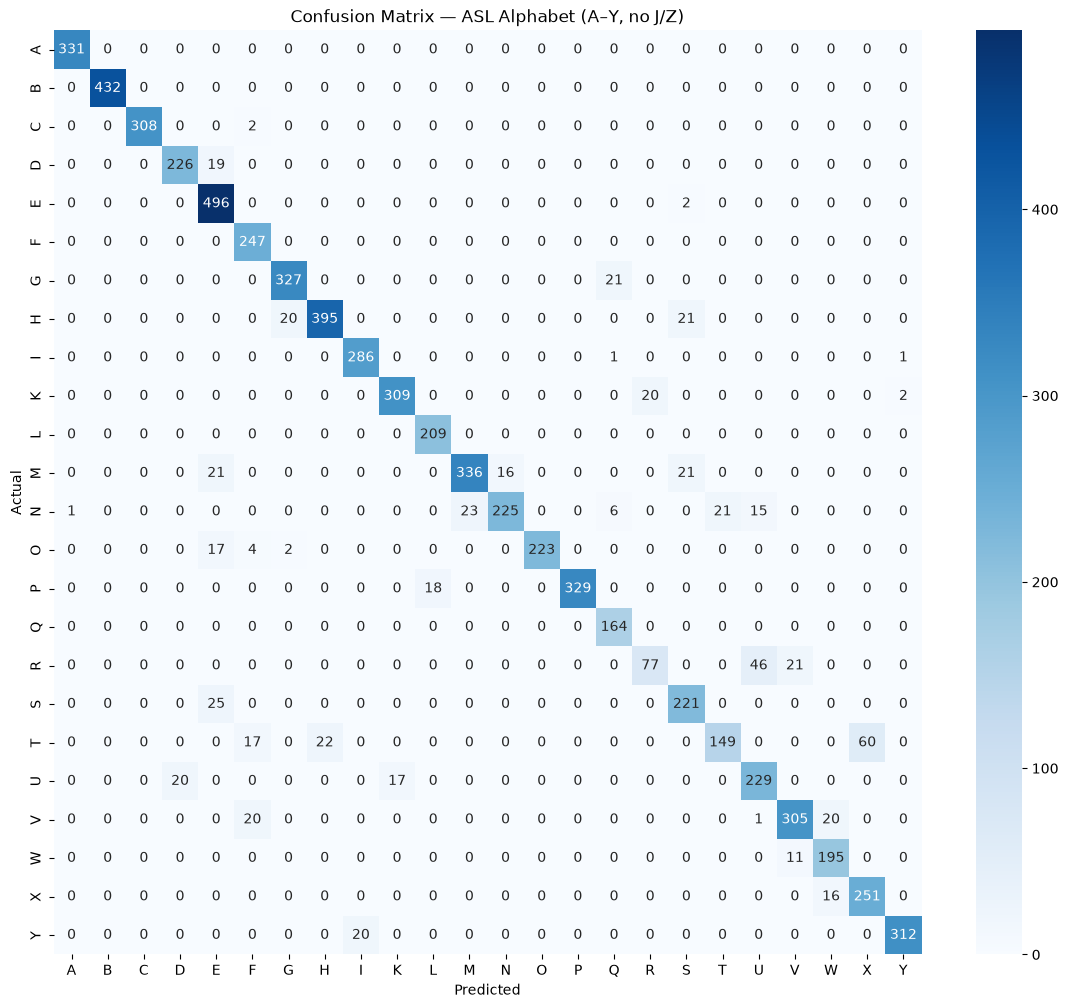

              precision    recall  f1-score   support

           A      0.997     1.000     0.998       331
           B      1.000     1.000     1.000       432
           C      1.000     0.994     0.997       310
           D      0.919     0.922     0.921       245
           E      0.858     0.996     0.922       498
           F      0.852     1.000     0.920       247
           G      0.937     0.940     0.938       348
           H      0.947     0.906     0.926       436
           I      0.935     0.993     0.963       288
           K      0.948     0.934     0.941       331
           L      0.921     1.000     0.959       209
           M      0.936     0.853     0.892       394
           N      0.934     0.773     0.846       291
           O      1.000     0.907     0.951       246
           P      1.000     0.948     0.973       347
           Q      0.854     1.000     0.921       164
           R      0.794     0.535     0.639       144
           S      0.834    

In [9]:
y_pred_prob = model.predict(x_test, verbose=0)
y_pred      = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=alphabet, yticklabels=alphabet)
plt.title('Confusion Matrix — ASL Alphabet (A–Y, no J/Z)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print(classification_report(y_test, y_pred, target_names=alphabet, digits=3))